# 03 · Experiment 2 — fusion strategies (voice + face image)

**Research question (Exp. 2):** Exp. 1 showed that simple concatenation lets the strong audio features outvote the image:
fake-voice clips are caught (100 %) but *fake-face-only* clips drop from 92 % (image alone) to 38 % (fused).
Which fusion strategy uses both modalities without one drowning out the other?

All systems use the **same frozen embeddings, same speaker-disjoint splits (seeds 42-46; seed 42 = Exp. 1's main split)** and are tuned on validation only.

| Family | System | Idea |
|---|---|---|
| reference | Audio only / Image only / Early concat (LR) | Exp. 1 numbers, recomputed here |
| **late fusion** (per-modality LR, then combine) | Mean prob | average the two modality probabilities |
| | Max prob | "fake if **either** modality says fake" |
| | Noisy-OR | 1 − (1−p_audio)(1−p_image) |
| | Stacked LR | meta-classifier on the two modality logits (out-of-fold, speaker-grouped) |
| **neural** (small PyTorch heads) | Concat-MLP | concatenate projected audio + image, MLP |
| | Gated fusion | learned gate g: `g·audio + (1−g)·image` |
| | Cross-attention | image token queries the 13 Wav2Vec2 layer tokens; learned-query pooling of audio; concat → head |
| | each of the three, **+ modality dropout** | randomly blank one modality in training so each must be predictive alone |

**Honest limitation of the cross-attention model:** the image is a single pooled CLIP vector (we saved the mean of 3 frame embeddings),
so "cross-attention" here is *image → audio-layer* attention. Patch-level image attention would need re-extraction.

Reported: accuracy / F1 / ROC-AUC (mean ± std over 5 splits), accuracy at a **validation-tuned threshold** (rules like max / noisy-OR shift the operating point),
and per-category accuracy (RVRA real · RVFA fake voice · FVRA fake face · FVFA both).

**How to run on Kaggle:** add your `FakeAVCeleb-features` dataset as the only input, accelerator **None or GPU** (both fine), Internet off,
normal **Run All**. First run with `QUICK = True` (1 split, 5 epochs, ~1 min) to check the neural cells; then set `QUICK = False`.
The classical results are saved before the neural part starts, so a neural bug can't lose them.

In [9]:
import os, glob, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, balanced_accuracy_score)

warnings.filterwarnings("ignore")
try:
    display
except NameError:
    display = lambda x: print(x.to_string() if hasattr(x, "to_string") else x)

QUICK = False
SEED = 42
N_SPLITS = 1 if QUICK else 5
EPOCHS = 5 if QUICK else 80
PATIENCE = 15
MOD_DROP = 0.3                                      # prob. that one modality is blanked per training sample
CS = [1e-3, 1e-2, 1e-1, 1, 10]
OUT = os.environ.get("EXP_OUT", "/kaggle/working/exp2")
os.makedirs(OUT, exist_ok=True)
CATS = ["RVRA", "RVFA", "FVRA", "FVFA"]

def find(name):
    cands = []
    if os.environ.get("FEAT_DIR"):
        cands.append(os.path.join(os.environ["FEAT_DIR"], name))
    cands.append(os.path.join("/kaggle/working/features", name))
    cands += glob.glob(f"/kaggle/input/**/{name}", recursive=True)
    for c in cands:
        if os.path.exists(c):
            return c
    raise FileNotFoundError(f"{name} not found. Add the FakeAVCeleb-features dataset as an input.")

FEAT_NPZ, META_CSV = find("features.npz"), find("meta.csv")
print("features:", FEAT_NPZ, "\nmeta:    ", META_CSV, "\nQUICK =", QUICK)

features: /kaggle/input/datasets/aryavartsinghpayal/fakeavceleb-features/features.npz 
meta:     /kaggle/input/datasets/aryavartsinghpayal/fakeavceleb-features/meta.csv 
QUICK = False


## 1 · Load features (identical to Exp. 1)

In [10]:
Z = np.load(FEAT_NPZ)
meta = pd.read_csv(META_CSV).sort_values("clip_id").reset_index(drop=True)
assert (Z["clip_id"] == meta.clip_id.values).all(), "features.npz and meta.csv are out of sync"
keep = ((meta.ok_img == 1) & (meta.ok_aud == 1)).values
meta = meta[keep].reset_index(drop=True)
A_LAYERS, IMG = Z["audio_layers"][keep], Z["image"][keep]
y = meta.label.values                    # 1 = FAKE
groups = meta.speaker.values
cats = meta.category.values
print("clips:", len(meta), "| REAL:", int((y == 0).sum()), "| FAKE:", int((y == 1).sum()))

def grouped_split(seed, val=0.15, test=0.15):
    idx = np.arange(len(y))
    trv, te = next(GroupShuffleSplit(1, test_size=test, random_state=seed).split(idx, groups=groups))
    a, b = next(GroupShuffleSplit(1, test_size=val / (1 - test), random_state=seed).split(trv, groups=groups[trv]))
    return trv[a], trv[b], te

SPLITS = [grouped_split(SEED + s) for s in range(N_SPLITS)]
te_main = np.where(meta.split == "test")[0]
print("split 0 test set identical to Exp. 1 main split:", set(SPLITS[0][2]) == set(te_main))

clips: 998 | REAL: 500 | FAKE: 498
split 0 test set identical to Exp. 1 main split: True


## 2 · Shared helpers

In [11]:
def metrics(yt, p, thr=0.5):
    yh = (p >= thr).astype(int)
    return dict(acc=accuracy_score(yt, yh), precision=precision_score(yt, yh, zero_division=0),
                recall=recall_score(yt, yh, zero_division=0), f1=f1_score(yt, yh, zero_division=0),
                roc_auc=roc_auc_score(yt, p), pr_auc=average_precision_score(yt, p))

def val_threshold(yv, pv):
    """threshold maximising balanced accuracy on validation; ties -> closest to 0.5"""
    grid = np.linspace(0.05, 0.95, 91)
    sc = np.array([balanced_accuracy_score(yv, (pv >= t).astype(int)) for t in grid])
    cand = grid[sc >= sc.max() - 1e-12]
    return float(cand[np.argmin(np.abs(cand - 0.5))])

def evaluate(system, split_id, pv, pt, va, te):
    m = metrics(y[te], pt)
    thr = val_threshold(y[va], pv)
    mv = metrics(y[te], pt, thr)
    rec = dict(split=split_id, system=system, **m, acc_vt=mv["acc"], f1_vt=mv["f1"], thr_vt=thr)
    pred = (pt >= 0.5).astype(int)
    for c in CATS:
        mk = cats[te] == c
        rec[f"acc_{c}"] = float((pred[mk] == y[te][mk]).mean()) if mk.any() else np.nan
    return rec

def scale(tr, *others):
    sc = StandardScaler().fit(tr)
    return (sc.transform(tr),) + tuple(sc.transform(o) for o in others)

def fit_lr(Xtr, ytr, Xva, yva):
    best = None
    for C in CS:
        clf = LogisticRegression(C=C, class_weight="balanced", max_iter=3000).fit(Xtr, ytr)
        auc = roc_auc_score(yva, clf.predict_proba(Xva)[:, 1])
        if best is None or auc > best[0]:
            best = (auc, C, clf)
    return best[2], best[1]

def choose_audio_layer(tr, va):
    best_layer, best_auc = None, -1
    for layer in ["mean"] + list(range(A_LAYERS.shape[1])):
        M = A_LAYERS.mean(1) if layer == "mean" else A_LAYERS[:, layer]
        a_tr, a_va = scale(M[tr], M[va])
        clf = LogisticRegression(C=0.1, class_weight="balanced", max_iter=2000).fit(a_tr, y[tr])
        auc = roc_auc_score(y[va], clf.predict_proba(a_va)[:, 1])
        if auc > best_auc:
            best_layer, best_auc = layer, auc
    return best_layer

logit = lambda p: np.log(np.clip(p, 1e-6, 1 - 1e-6) / (1 - np.clip(p, 1e-6, 1 - 1e-6)))

## 3 · Classical systems: single modalities, early concat, and four late-fusion rules

In [12]:
def classical_split(tr, va, te):
    layer = choose_audio_layer(tr, va)
    M = A_LAYERS.mean(1) if layer == "mean" else A_LAYERS[:, layer]
    A = scale(M[tr], M[va], M[te])
    I = scale(IMG[tr], IMG[va], IMG[te])
    P = {}                                                   # per-modality probabilities
    for k, X in (("A", A), ("I", I)):
        clf, C = fit_lr(X[0], y[tr], X[1], y[va])
        P[k] = dict(C=C, va=clf.predict_proba(X[1])[:, 1], te=clf.predict_proba(X[2])[:, 1], X=X)

    # early concat reference
    Xc = [np.hstack([A[j], I[j]]) for j in range(3)]
    clf, _ = fit_lr(Xc[0], y[tr], Xc[1], y[va])
    out = {"Audio only": (P["A"]["va"], P["A"]["te"]),
           "Image only": (P["I"]["va"], P["I"]["te"]),
           "Early concat (LR)": (clf.predict_proba(Xc[1])[:, 1], clf.predict_proba(Xc[2])[:, 1])}

    # late-fusion rules on the two per-modality probabilities
    rules = {"Late: mean prob": lambda a, i: (a + i) / 2,
             "Late: max prob (either says fake)": lambda a, i: np.maximum(a, i),
             "Late: noisy-OR": lambda a, i: 1 - (1 - a) * (1 - i)}
    for name, f in rules.items():
        out[name] = (f(P["A"]["va"], P["I"]["va"]), f(P["A"]["te"], P["I"]["te"]))

    # stacked LR on out-of-fold train probabilities (speaker-grouped CV -> no identity leakage)
    oof = {k: np.zeros(len(tr)) for k in P}
    for itr, iva in GroupKFold(n_splits=5).split(tr, groups=groups[tr]):
        for k in P:
            m = LogisticRegression(C=P[k]["C"], class_weight="balanced", max_iter=3000).fit(P[k]["X"][0][itr], y[tr][itr])
            oof[k][iva] = m.predict_proba(P[k]["X"][0][iva])[:, 1]
    meta_clf = LogisticRegression(C=1.0, class_weight="balanced", max_iter=1000).fit(
        np.c_[logit(oof["A"]), logit(oof["I"])], y[tr])
    stack = lambda s: meta_clf.predict_proba(np.c_[logit(P["A"][s]), logit(P["I"][s])])[:, 1]
    out["Late: stacked LR"] = (stack("va"), stack("te"))
    return out, layer

records, test_probs = [], {}
t0 = time.time()
for s, (tr, va, te) in enumerate(SPLITS):
    out, layer = classical_split(tr, va, te)
    for name, (pv, pt) in out.items():
        records.append(evaluate(name, s, pv, pt, va, te))
    if s == 0:
        test_probs.update({k: v[1] for k, v in out.items()})
    print(f"split {s}: audio layer={layer}  ({time.time() - t0:.0f}s)")
df_classical = pd.DataFrame(records)
df_classical.to_csv(f"{OUT}/exp2_classical_per_split.csv", index=False)
print("saved classical per-split results")

split 0: audio layer=mean  (19s)
split 1: audio layer=2  (37s)
split 2: audio layer=0  (57s)
split 3: audio layer=0  (80s)
split 4: audio layer=3  (99s)
saved classical per-split results


## 4 · Neural systems (PyTorch)
Small heads on the frozen features, 693 train clips, so each model trains in seconds.
Inputs are standardised with **train-only** statistics. Early stopping on validation AUC.

In [13]:
try:
    import torch, torch.nn as nn
    HAVE_TORCH = True
except Exception as e:
    HAVE_TORCH = False
    print("PyTorch not available -> neural systems skipped:", e)

if HAVE_TORCH:
    dev = "cuda" if torch.cuda.is_available() else "cpu"
    print("device:", dev)

    def proj(d_in, d, p):
        return nn.Sequential(nn.Dropout(p), nn.Linear(d_in, d), nn.LayerNorm(d), nn.GELU())

    class ConcatMLP(nn.Module):
        def __init__(s, d=128, p=0.3):
            super().__init__()
            s.pa, s.pi = proj(768, d, p), proj(512, d, p)
            s.head = nn.Sequential(nn.Dropout(p), nn.Linear(2 * d, d), nn.GELU(), nn.Linear(d, 1))
        def forward(s, a, i):                                    # a: (B,13,768)  i: (B,512)
            return s.head(torch.cat([s.pa(a.mean(1)), s.pi(i)], -1)).squeeze(-1)

    class Gated(nn.Module):
        def __init__(s, d=128, p=0.3):
            super().__init__()
            s.pa, s.pi = proj(768, d, p), proj(512, d, p)
            s.gate = nn.Linear(2 * d, d)
            s.head = nn.Sequential(nn.Dropout(p), nn.Linear(d, 1))
        def forward(s, a, i):
            ha, hi = s.pa(a.mean(1)), s.pi(i)
            g = torch.sigmoid(s.gate(torch.cat([ha, hi], -1)))
            return s.head(g * ha + (1 - g) * hi).squeeze(-1)

    class CrossAttn(nn.Module):
        """image token queries the 13 audio-layer tokens; a learned query pools the audio tokens; concat -> head"""
        def __init__(s, d=128, p=0.3, heads=4):
            super().__init__()
            s.pa, s.pi = proj(768, d, p), proj(512, d, p)
            s.layer_pos = nn.Parameter(torch.zeros(A_LAYERS.shape[1], d))
            s.q_pool = nn.Parameter(torch.randn(1, 1, d) * 0.02)
            s.pool = nn.MultiheadAttention(d, heads, dropout=p, batch_first=True)
            s.cross = nn.MultiheadAttention(d, heads, dropout=p, batch_first=True)
            s.norm = nn.LayerNorm(d)
            s.head = nn.Sequential(nn.Dropout(p), nn.Linear(3 * d, d), nn.GELU(), nn.Linear(d, 1))
        def forward(s, a, i):
            ta = s.pa(a) + s.layer_pos                           # (B,13,d)
            ti = s.pi(i).unsqueeze(1)                            # (B,1,d)
            pooled, _ = s.pool(s.q_pool.expand(len(a), -1, -1), ta, ta)
            ctx, _ = s.cross(ti, ta, ta)
            ctx = s.norm(ti + ctx)
            return s.head(torch.cat([pooled, ti, ctx], -1).squeeze(1)).squeeze(-1)

    KINDS = {"Concat-MLP": ConcatMLP, "Gated fusion": Gated, "Cross-attention (image→audio layers)": CrossAttn}

    def prep_tensors(tr):
        mu, sd = A_LAYERS[tr].mean(0, keepdims=True), A_LAYERS[tr].std(0, keepdims=True) + 1e-6
        mi, si = IMG[tr].mean(0, keepdims=True), IMG[tr].std(0, keepdims=True) + 1e-6
        Xa = torch.tensor((A_LAYERS - mu) / sd, dtype=torch.float32, device=dev)
        Xi = torch.tensor((IMG - mi) / si, dtype=torch.float32, device=dev)
        return Xa, Xi

    def train_neural(cls, Xa, Xi, tr, va, te, mod_drop, seed):
        torch.manual_seed(seed); np.random.seed(seed)
        model = cls().to(dev)
        opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)
        lossf = nn.BCEWithLogitsLoss()
        yt = torch.tensor(y, dtype=torch.float32, device=dev)
        tr_t, va_t, te_t = (torch.as_tensor(ix, device=dev) for ix in (tr, va, te))
        best_auc, best_state, bad = -1.0, None, 0
        for ep in range(EPOCHS):
            model.train()
            perm = tr_t[torch.randperm(len(tr_t), device=dev)]
            for k in range(0, len(perm), 64):
                idx = perm[k:k + 64]
                a, i, t = Xa[idx], Xi[idx], yt[idx]
                if mod_drop > 0:                                 # blank audio w.p. p/2, image w.p. p/2 (never both)
                    r = torch.rand(len(idx), device=dev)
                    a = a * (r >= mod_drop / 2).float()[:, None, None]
                    i = i * ((r < mod_drop / 2) | (r >= mod_drop)).float()[:, None]
                loss = lossf(model(a, i), t)
                opt.zero_grad(); loss.backward(); opt.step()
            model.eval()
            with torch.no_grad():
                pv = torch.sigmoid(model(Xa[va_t], Xi[va_t])).cpu().numpy()
            auc = roc_auc_score(y[va], pv)
            if auc > best_auc:
                best_auc, bad = auc, 0
                best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
            else:
                bad += 1
                if bad >= PATIENCE:
                    break
        model.load_state_dict(best_state); model.eval()
        with torch.no_grad():
            pv = torch.sigmoid(model(Xa[va_t], Xi[va_t])).cpu().numpy()
            pt = torch.sigmoid(model(Xa[te_t], Xi[te_t])).cpu().numpy()
        return pv, pt

    nrecords, t0 = [], time.time()
    for s, (tr, va, te) in enumerate(SPLITS):
        Xa, Xi = prep_tensors(tr)
        for kname, cls in KINDS.items():
            for md in (0.0, MOD_DROP):
                name = kname + (" + modality dropout" if md > 0 else "")
                pv, pt = train_neural(cls, Xa, Xi, tr, va, te, md, seed=SEED + s)
                nrecords.append(evaluate(name, s, pv, pt, va, te))
                if s == 0:
                    test_probs[name] = pt
        print(f"split {s} neural done ({time.time() - t0:.0f}s)")
    df_neural = pd.DataFrame(nrecords)
    df_neural.to_csv(f"{OUT}/exp2_neural_per_split.csv", index=False)
else:
    df_neural = pd.DataFrame()

device: cpu
split 0 neural done (32s)
split 1 neural done (67s)
split 2 neural done (93s)
split 3 neural done (127s)
split 4 neural done (159s)


## 5 · Results — mean ± std over splits

In [14]:
df = pd.concat([df_classical, df_neural], ignore_index=True)
df.to_csv(f"{OUT}/exp2_all_per_split.csv", index=False)
order = [n for n in ["Audio only", "Image only", "Early concat (LR)", "Late: mean prob", "Late: max prob (either says fake)",
                     "Late: noisy-OR", "Late: stacked LR", "Concat-MLP", "Concat-MLP + modality dropout", "Gated fusion",
                     "Gated fusion + modality dropout", "Cross-attention (image→audio layers)",
                     "Cross-attention (image→audio layers) + modality dropout"] if n in set(df.system)]
cols = ["acc", "f1", "roc_auc", "acc_vt"] + [f"acc_{c}" for c in CATS]
g = df.groupby("system")[cols]
summary = g.mean().loc[order].round(3)
sd = g.std().loc[order].round(3)
print(f"mean over {N_SPLITS} speaker-disjoint split(s)   [acc_vt = accuracy at validation-tuned threshold]\n")
display(summary)
if N_SPLITS > 1:
    print("\nstd over splits (note: splits overlap, so this understates true uncertainty)\n")
    display(sd)
summary.to_csv(f"{OUT}/exp2_summary_mean.csv"); sd.to_csv(f"{OUT}/exp2_summary_std.csv")

mean over 5 speaker-disjoint split(s)   [acc_vt = accuracy at validation-tuned threshold]



,acc,f1,roc_auc,acc_vt,acc_RVRA,acc_RVFA,acc_FVRA,acc_FVFA
system,,,,,,,,
Audio only,0.777,0.759,0.832,0.791,0.840,1.000,0.196,0.960
Image only,0.724,0.709,0.786,0.699,0.752,0.338,0.903,0.827
Early concat (LR),0.851,0.842,0.937,0.850,0.901,0.970,0.467,0.985
Late: mean prob,0.828,0.820,0.922,0.833,0.856,1.000,0.452,0.957
Late: max prob (either says fake),0.802,0.830,0.934,0.858,0.629,1.000,0.939,0.988
Late: noisy-OR,0.725,0.781,0.934,0.847,0.464,1.000,0.972,1.000
Late: stacked LR,0.859,0.856,0.932,0.846,0.867,0.990,0.590,0.979
Concat-MLP,0.872,0.861,0.938,0.875,0.931,1.000,0.453,1.000
Concat-MLP + modality dropout,0.876,0.864,0.933,0.863,0.952,0.993,0.423,1.000



std over splits (note: splits overlap, so this understates true uncertainty)



,acc,f1,roc_auc,acc_vt,acc_RVRA,acc_RVFA,acc_FVRA,acc_FVFA
system,,,,,,,,
Audio only,0.046,0.047,0.046,0.044,0.110,0.000,0.149,0.058
Image only,0.012,0.045,0.025,0.031,0.072,0.162,0.038,0.116
Early concat (LR),0.019,0.014,0.015,0.019,0.031,0.044,0.104,0.021
Late: mean prob,0.060,0.054,0.037,0.044,0.103,0.000,0.145,0.029
Late: max prob (either says fake),0.057,0.040,0.039,0.037,0.126,0.000,0.046,0.028
Late: noisy-OR,0.031,0.012,0.037,0.050,0.094,0.000,0.040,0.000
Late: stacked LR,0.043,0.037,0.034,0.043,0.091,0.021,0.144,0.029
Concat-MLP,0.020,0.020,0.015,0.023,0.050,0.000,0.143,0.000
Concat-MLP + modality dropout,0.021,0.018,0.014,0.032,0.024,0.015,0.071,0.000


## 6 · Paired comparison vs. early concatenation
Same splits for every system, so differences are paired. `wins` = number of splits where the system beats early concat.

In [15]:
base = df[df.system == "Early concat (LR)"].set_index("split")
rows = []
for n in order:
    if n == "Early concat (LR)":
        continue
    d = df[df.system == n].set_index("split")
    rows.append({"system": n,
                 "ΔAUC": (d.roc_auc - base.roc_auc).mean(), "AUC wins": f"{int((d.roc_auc > base.roc_auc).sum())}/{len(d)}",
                 "Δacc FVRA": (d.acc_FVRA - base.acc_FVRA).mean(), "FVRA wins": f"{int((d.acc_FVRA > base.acc_FVRA).sum())}/{len(d)}",
                 "Δacc RVRA (real)": (d.acc_RVRA - base.acc_RVRA).mean(), "Δacc overall": (d.acc - base.acc).mean()})
paired = pd.DataFrame(rows).set_index("system").round(3)
display(paired)
paired.to_csv(f"{OUT}/exp2_paired_vs_early_concat.csv")

,ΔAUC,AUC wins,Δacc FVRA,FVRA wins,Δacc RVRA (real),Δacc overall
system,,,,,,
Audio only,-0.105,0/5,-0.271,0/5,-0.061,-0.074
Image only,-0.151,0/5,0.436,5/5,-0.149,-0.127
Late: mean prob,-0.015,2/5,-0.015,3/5,-0.045,-0.024
Late: max prob (either says fake),-0.003,3/5,0.472,5/5,-0.272,-0.050
Late: noisy-OR,-0.003,3/5,0.505,5/5,-0.437,-0.126
Late: stacked LR,-0.005,2/5,0.123,4/5,-0.035,0.007
Concat-MLP,0.001,3/5,-0.014,2/5,0.029,0.020
Concat-MLP + modality dropout,-0.004,2/5,-0.044,1/5,0.051,0.025
Gated fusion,0.001,2/5,0.003,2/5,0.035,0.025


## 7 · Figures
(1) ROC-AUC per system, mean ± std. (2) Per-category accuracy — where each fusion strategy wins or loses.

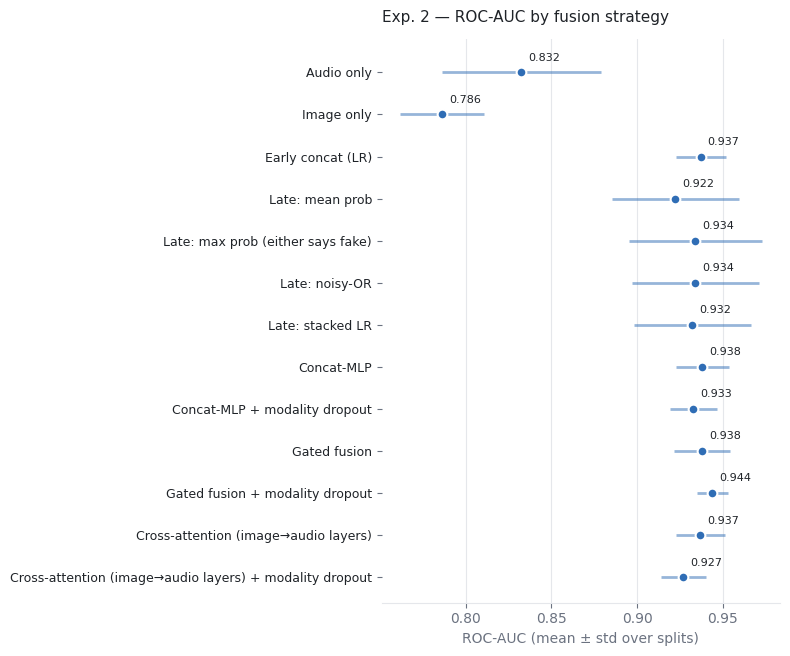

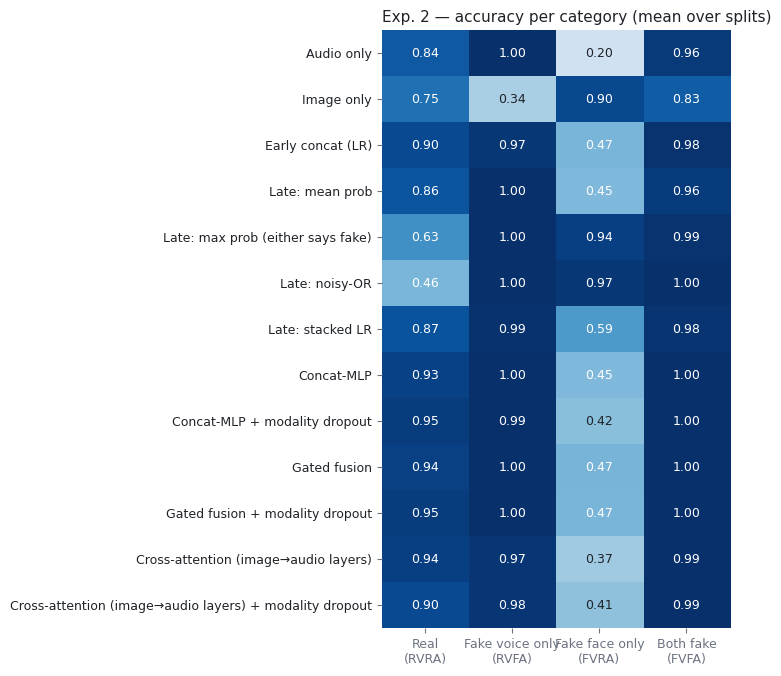

In [16]:
INK, MUTED, GRID, BLUE = "#1f2328", "#6b7280", "#e5e7eb", "#2f6db5"
plt.rcParams.update({"font.size": 10, "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED})

fig, ax = plt.subplots(figsize=(8, 0.42 * len(order) + 1.2))
yy = np.arange(len(order))[::-1]
mu_auc = df.groupby("system").roc_auc.mean().loc[order].values
sd_auc = df.groupby("system").roc_auc.std().loc[order].fillna(0).values
ax.hlines(yy, mu_auc - sd_auc, mu_auc + sd_auc, color=BLUE, lw=2, alpha=0.5)
ax.plot(mu_auc, yy, "o", color=BLUE, ms=7, mec="white", mew=1.5)
for x, yv in zip(mu_auc, yy):
    ax.text(x + 0.004, yv + 0.28, f"{x:.3f}", fontsize=8, color=INK)
ax.set_yticks(yy); ax.set_yticklabels(order, color=INK, fontsize=9)
ax.set_xlabel("ROC-AUC (mean ± std over splits)")
ax.grid(axis="x", color=GRID, lw=0.8); ax.set_axisbelow(True)
for sp in ("top", "right", "left"): ax.spines[sp].set_visible(False)
ax.set_ylim(-0.6, len(order) - 0.2)
ax.set_title("Exp. 2 — ROC-AUC by fusion strategy", loc="left", color=INK, fontsize=11, pad=12)
plt.tight_layout(); plt.savefig(f"{OUT}/exp2_auc.png", dpi=170); plt.show()

fig, ax = plt.subplots(figsize=(7.5, 0.42 * len(order) + 1.4))
M = summary[[f"acc_{c}" for c in CATS]].values
im = ax.imshow(M, cmap="Blues", vmin=0, vmax=1, aspect="auto")
for i in range(M.shape[0]):
    for j in range(M.shape[1]):
        ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=9, color="white" if M[i, j] > 0.45 else INK)
ax.set_xticks(range(4)); ax.set_xticklabels(["Real\n(RVRA)", "Fake voice only\n(RVFA)", "Fake face only\n(FVRA)", "Both fake\n(FVFA)"], fontsize=9)
ax.set_yticks(range(len(order))); ax.set_yticklabels(order, color=INK, fontsize=9)
for sp in ax.spines.values(): sp.set_visible(False)
ax.set_title("Exp. 2 — accuracy per category (mean over splits)", loc="left", color=INK, fontsize=11)
plt.tight_layout(); plt.savefig(f"{OUT}/exp2_per_category.png", dpi=170); plt.show()